In [1]:
import os, sys, glob, io, contextlib, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').setLevel(logging.ERROR)
logging.getLogger('harmonypy').propagate=False
logging.getLogger('harmonypy').disabled=True

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
# unconditional EMT-TF step (always the LAST notebook). Load signatures (pseudotime + house layout).
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 1061 | pseudotime 0.0 -> 11.54


In [4]:
# score a WIDE EMT-TF panel (Snail/Zeb/Twist + FOXC/PRRX mesenchymal families; VIM excluded -
# a mesenchymal marker, NOT a TF). Gate on detectable expression; classify each by pseudotime end.
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x = X[:,j]; expr = x>0; rho,_ = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(origin)', 'LATE(terminus)')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
body_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']       # least terminal (origin/body)
terminus_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']  # most terminal
print(f'\nexpressed EMT-TFs (frac>3%): {len(ok)}')
print(f'origin/body factor (min rho) = {body_tf}; terminus factor (max rho) = {terminus_tf}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
TWIST1      0.101       0.246      0.237     0.025  EARLY(origin)
 FOXC1      0.072       0.079      0.195     0.090 LATE(terminus)
TWIST2      0.016       0.028      0.116     0.104 LATE(terminus)
 PRRX1      0.093       0.122      0.303     0.140 LATE(terminus)
 SNAI1      0.100       0.160      0.472     0.151 LATE(terminus)
  ZEB1      0.109       0.178      0.424     0.179 LATE(terminus)
  ZEB2      0.778       2.131      3.001     0.194 LATE(terminus)
 SNAI2      0.355       1.037      2.284     0.246 LATE(terminus)

expressed EMT-TFs (frac>3%): 7
origin/body factor (min rho) = TWIST1; terminus factor (max rho) = SNAI2


overlay thresholds (upper quartile among expressers): {'TWIST1': 3.56, 'SNAI2': 5.42} | cells shown: {'TWIST1': 27, 'SNAI2': 94}
TWIST1: 10.1% expressing; 27 shown; mean pseudotime of shown = 0.48
SNAI2: 35.5% expressing; 94 shown; mean pseudotime of shown = 0.58
saved expression.pdf


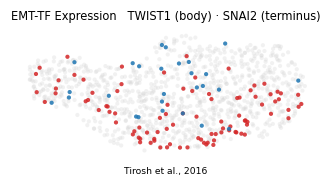

In [5]:
# categorical overlay: thresholded expressers of the two chosen TFs on a grey manifold (reference style)
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [body_tf, terminus_tf]:
    v = vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: vec(g) > thr[g] for g in [body_tf, terminus_tf]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],2) for g in thr},
      '| cells shown:', {g:int(sel[g].sum()) for g in sel})
order = sorted([body_tf, terminus_tf], key=lambda g: -int(sel[g].sum()))
colors = {body_tf:'tab:blue', terminus_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {body_tf} (body) \u00b7 {terminus_tf} (terminus)', size=7.5)
ax.text(.5,-.14,'Tirosh et al., 2016', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [body_tf, terminus_tf]:
    m = sel[g]
    print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pseudotime of shown = {tn[m].mean():.2f}')
print('saved expression.pdf')